In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import spacy

# Load dataset
df = pd.read_csv("fakenews.csv")

# Load English NLP model
nlp = spacy.load("en_core_web_sm")

In [2]:
# Handle missing values
df["headline"] = df["headline"].fillna("").astype(str)
df["body_text"] = df["body_text"].fillna("").astype(str)

# Combine headline and body text
df["text"] = df["headline"] + " " + df["body_text"]

# Display dataset
print(df[["label", "text"]].head())

print("\nTotal articles:", len(df))

  label                                               text
0  Real  Global economy faces recession The Prime Minis...
1  Real  Earthquake hits Chittagong, panic spreads Gove...
2  Fake  Breakthrough in Bangladesh's tech industry Loc...
3  Fake  Dengue situation worsens in the country The Pr...
4  Real  New virus outbreak sparks fear Government sour...

Total articles: 2212


In [3]:
# Identify active and passive voice in each sentence

voice_records = []

for idx, row in df.iterrows():
    doc = nlp(row["text"])

    for sent in doc.sents:
        # Check passive voice indicators
        passive_deps = {
            "nsubjpass", "auxpass",
            "nsubj:pass", "aux:pass"
        }

        is_passive = any(
            token.dep_ in passive_deps
            for token in sent
        )

        has_verb = any(
            token.pos_ in ["VERB", "AUX"]
            for token in sent
        )

        if is_passive:
            voice = "Passive"
        elif has_verb:
            voice = "Active"
        else:
            voice = "Other"

        voice_records.append({
            "news_id": row.get("news_id", idx),
            "label": row["label"],
            "sentence": sent.text.strip(),
            "voice": voice
        })

# Convert results into a DataFrame
voice_df = pd.DataFrame(voice_records)

# Display results
print(voice_df.head(10))

print("\nVoice distribution:")
print(voice_df["voice"].value_counts())

   news_id label                                           sentence    voice
0        1  Real  Global economy faces recession The Prime Minis...   Active
1        2  Real  Earthquake hits Chittagong, panic spreads Gove...  Passive
2        3  Fake  Breakthrough in Bangladesh's tech industry Loc...   Active
3        4  Fake  Dengue situation worsens in the country The Pr...   Active
4        5  Real  New virus outbreak sparks fear Government sour...  Passive
5        6  Fake  Earthquake hits Chittagong, panic spreads Doct...   Active
6        7  Fake  Global economy faces recession Government sour...  Passive
7        8  Real  Global economy faces recession Many are callin...   Active
8        8  Real           However, experts say it's quite natural.   Active
9        9  Fake  Earthquake hits Chittagong, panic spreads Doct...   Active

Voice distribution:
voice
Active     2297
Passive     418
Name: count, dtype: int64


In [4]:
# Keep only active and passive sentences
classified = voice_df[voice_df["voice"].isin(["Active", "Passive"])]

# Count active and passive sentences in each article
voice_counts = (
    classified.groupby(["news_id", "label", "voice"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure both columns exist
for col in ["Active", "Passive"]:
    if col not in voice_counts.columns:
        voice_counts[col] = 0

# Calculate total classified sentences
voice_counts["total_sentences"] = (
    voice_counts["Active"] + voice_counts["Passive"]
)

# Calculate percentages
voice_counts["active_percentage"] = (
    voice_counts["Active"] / voice_counts["total_sentences"] * 100
)

voice_counts["passive_percentage"] = (
    voice_counts["Passive"] / voice_counts["total_sentences"] * 100
)

# Display results
print(voice_counts.head(10))

voice  news_id label  Active  Passive  total_sentences  active_percentage  \
0            1  Real       1        0                1              100.0   
1            2  Real       0        1                1                0.0   
2            3  Fake       1        0                1              100.0   
3            4  Fake       1        0                1              100.0   
4            5  Real       0        1                1                0.0   
5            6  Fake       1        0                1              100.0   
6            7  Fake       0        1                1                0.0   
7            8  Real       2        0                2              100.0   
8            9  Fake       1        0                1              100.0   
9           10  Real       1        1                2               50.0   

voice  passive_percentage  
0                     0.0  
1                   100.0  
2                     0.0  
3                     0.0  
4           

In [5]:
# Compare average voice percentages by news label
comparison = (
    voice_counts.groupby("label")[
        ["active_percentage", "passive_percentage"]
    ]
    .mean()
    .round(2)
)

# Display comparison
print("Active vs Passive Voice in Real and Fake News:\n")
print(comparison)

Active vs Passive Voice in Real and Fake News:

voice  active_percentage  passive_percentage
label                                       
Fake               84.86               15.14
Real               87.39               12.61


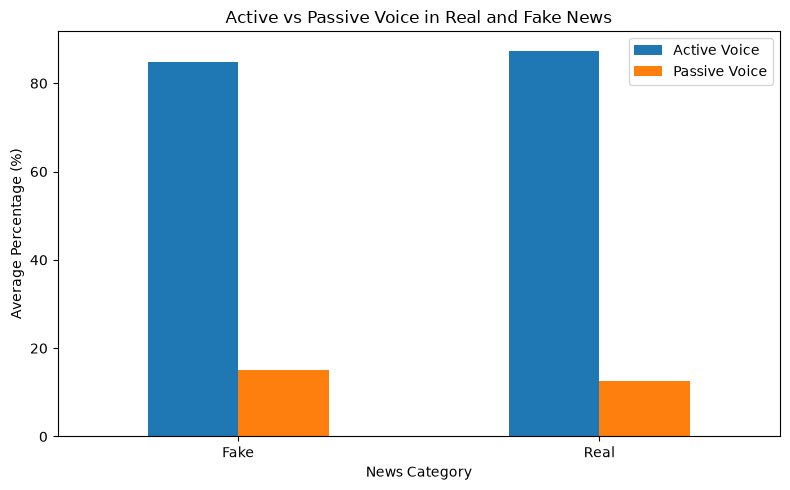

In [6]:
# Plot active and passive voice percentages
comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Active vs Passive Voice in Real and Fake News")
plt.xlabel("News Category")
plt.ylabel("Average Percentage (%)")
plt.xticks(rotation=0)
plt.legend(["Active Voice", "Passive Voice"])
plt.tight_layout()
plt.show()

In [7]:
# Save sentence-level voice analysis
voice_df.to_csv("T21_voice_analysis.csv", index=False)

# Save article-level voice percentages
voice_counts.to_csv("T21_voice_percentages.csv", index=False)

# Display comparison
print("Average Active and Passive Voice Percentages:\n")
print(comparison)

# Find which category has a higher passive voice percentage
if "Fake" in comparison.index and "Real" in comparison.index:
    fake_passive = comparison.loc["Fake", "passive_percentage"]
    real_passive = comparison.loc["Real", "passive_percentage"]

    if fake_passive > real_passive:
        print("\nFake news has a higher average passive voice percentage.")
    elif real_passive > fake_passive:
        print("\nReal news has a higher average passive voice percentage.")
    else:
        print("\nBoth categories have the same average passive voice percentage.")

print("\nAnalysis completed successfully!")

Average Active and Passive Voice Percentages:

voice  active_percentage  passive_percentage
label                                       
Fake               84.86               15.14
Real               87.39               12.61

Fake news has a higher average passive voice percentage.

Analysis completed successfully!
